# Image Captioning with a Vision-Language Model — Flickr8k
**Models**
- **A. Scratch decoder** (main, 3 seeds): frozen pretrained **CLIP ViT-B/32** image encoder (LAION-400M) -> 50 visual tokens -> 3-layer transformer decoder with cross-attention (7.6M params) trained from scratch -> beam search.
- **B. CLIP-text-pretrained decoder** (ablation, 1 seed): the first 6 layers + embeddings of the **pretrained CLIP text transformer** (causal mask) + new zero-initialised cross-attention to the image tokens (28M params). This gives the language side a pretrained start.
**Not done (and why):** BLIP / GIT / GPT-2 fine-tuning — HuggingFace and other weight hosts are blocked in my sandbox (tested). So this is a CLIP-based VLM captioner, *not* a fine-tuned BLIP. A Colab BLIP script would be untested here, so I did not include one.
**Data:** Flickr8k (8,091 images x 5 captions; official 6000/1000/1000 split) from the jbrownlee GitHub release (Kaggle unreachable; one stray token-file key dropped; Kaggle copy may differ by a file).

In [1]:
import os, sys, json, numpy as np, torch, pandas as pd, matplotlib.pyplot as plt, textwrap
from PIL import Image
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd())=='notebooks' else os.getcwd(); sys.path.insert(0, ROOT); os.chdir(ROOT)
from ml.data import load_flickr8k, Vocab
from ml.model import Captioner
from ml.train import load_feats
DATA = os.environ.get('FLICKR_DATA', 'data')
caps, split, imgdir = load_flickr8k(DATA); idx, tok, G = load_feats('features')
print({k: len(v) for k, v in split.items()}, 'images with 5 captions:', len(caps))

{'train': 6000, 'val': 1000, 'test': 1000} images with 5 captions: 8091


## 1. Test scores (1,000 test images, 5 refs each; pycocoevalcap, PTB tokenizer, Java METEOR; x100)
One model per row, seed 0 unless stated. Baselines are retrieval/constant captions.

In [2]:
cols = ['BLEU-1','BLEU-2','BLEU-3','BLEU-4','METEOR','ROUGE-L','CIDEr']
S = json.load(open('results/test_scores.json')); df = pd.DataFrame(S).T.mul(100).round(1)[cols]
S2 = json.load(open('results_cliptext/test_scores.json'))['Decoder (CLIP tokens, beam=3)']; df.loc['CLIP-text-pretrained decoder (beam=3, 1 seed)'] = [round(S2[c]*100,1) for c in cols]
df.sort_values('CIDEr', ascending=False)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr
"Decoder (CLIP tokens, beam=3)",70.9,54.0,40.0,29.1,23.9,52.7,75.4
"CLIP-text-pretrained decoder (beam=3, 1 seed)",68.8,52.0,38.2,27.4,24.4,51.8,73.0
Decoder (greedy),68.0,50.6,36.2,25.6,23.2,51.1,68.6
CLIP image -> best train caption,53.4,33.8,20.7,12.5,19.5,40.3,42.2
NN image -> copy caption,48.8,29.8,18.0,10.9,16.9,38.0,32.1
Constant caption,42.3,23.8,13.7,8.6,12.0,33.5,9.1


## 2. Seeds: mean ± std over 3 seeds (scratch decoder) vs the pretrained-text variant

In [3]:
R = json.load(open('results_summary.json'))
rows = {k: {c: (f"{v[c][0]:.1f} ± {v[c][1]:.1f}" if v[c][1] is not None else f"{v[c][0]:.1f}") for c in cols} for k, v in R.items()}
pd.DataFrame(rows).T

,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr
Scratch decoder (3 seeds),70.0 ± 0.8,52.9 ± 1.0,38.9 ± 1.0,28.1 ± 0.9,24.1 ± 0.3,52.3 ± 0.6,73.8 ± 2.1
CLIP-text-pretrained decoder (1 seed),68.8,52.0,38.2,27.4,24.4,51.8,73.0


**Reading it:** the scratch decoder is stable across seeds (CIDEr std ~2). The CLIP-text-pretrained variant reaches the *same* quality (CIDEr 73.0 vs 73.8±2.1, inside seed noise) — it converges faster (dev CIDEr 0.57 after epoch 1 vs 0.25) but gives **no final gain** on Flickr8k. I report this as measured, not as a win.

## 3. Uncertainty over test images + reference-free CLIPScore
Bootstrap (1,000 resamples of the 1,000 test images) 95% CI. CLIPScore = 2.5·max(cos(image, caption),0) with the same CLIP model — it needs no references so it does not penalise valid-but-different captions. **Caveat:** CLIP-retrieval picks captions by CLIP similarity, so it is *favoured* by CLIPScore (circular); the human references score 0.78 for the same reason (CLIP is not perfect).

In [4]:
E = json.load(open('results/extra_metrics.json')); E2 = json.load(open('results_cliptext/extra_metrics.json'))
rows = []
for name, d, k in [('Scratch decoder seed0 (beam)', E, 'Decoder (CLIP tokens, beam=3)'), ('Scratch decoder seed1', json.load(open('results_seed1/extra_metrics.json')), 'Decoder (CLIP tokens, beam=3)'), ('Scratch decoder seed2', json.load(open('results_seed2/extra_metrics.json')), 'Decoder (CLIP tokens, beam=3)'), ('CLIP-text-pretrained decoder', E2, 'Decoder (CLIP tokens, beam=3)'), ('CLIP image -> best train caption', E, 'CLIP image -> best train caption'), ('NN image -> copy caption', E, 'NN image -> copy caption'), ('Constant caption', E, 'Constant caption')]:
    c = d[k]['CLIPScore']; ci = d[k]['CIDEr_per_image_mean']; rows.append((name, f"{c[0]:.3f} [{c[1]:.3f}, {c[2]:.3f}]", f"{ci[0]*100:.1f} [{ci[1]*100:.1f}, {ci[2]*100:.1f}]"))
rows.append(('Human reference #1', f"{E['Human reference #1 (CLIPScore only)']['CLIPScore'][0]:.3f}", '-'))
pd.DataFrame(rows, columns=['Model', 'CLIPScore [95% CI]', 'mean per-image CIDEr [95% CI]'])

,Model,CLIPScore [95% CI],mean per-image CIDEr [95% CI]
0,Scratch decoder seed0 (beam),"0.717 [0.710, 0.725]","75.5 [71.3, 79.7]"
1,Scratch decoder seed1,"0.726 [0.719, 0.733]","74.6 [70.7, 78.8]"
2,Scratch decoder seed2,"0.717 [0.709, 0.725]","71.5 [67.5, 75.6]"
3,CLIP-text-pretrained decoder,"0.732 [0.724, 0.739]","73.1 [69.0, 77.2]"
4,CLIP image -> best train caption,"0.848 [0.843, 0.852]","42.3 [39.6, 45.4]"
5,NN image -> copy caption,"0.642 [0.633, 0.651]","32.2 [29.9, 34.7]"
6,Constant caption,"0.134 [0.126, 0.142]","9.2 [8.3, 10.1]"
7,Human reference #1,0.780,-


In [5]:
h = json.load(open('results/history.json')); pd.DataFrame(h).round(3)

,epoch,train_loss,val_nll,val_cider_greedy,sec
0,1,5.804,3.589,0.253,259.843
1,2,4.126,3.021,0.502,515.639
2,3,3.774,2.823,0.602,770.805
3,4,3.596,2.723,0.647,1018.250
4,5,3.476,2.653,0.670,1267.270
5,6,3.385,2.619,0.697,1523.607
6,7,3.309,2.578,0.688,1788.968
7,8,3.248,2.561,0.689,2045.753
8,9,3.194,2.535,0.767,2304.188
9,10,3.149,2.539,0.681,2564.056


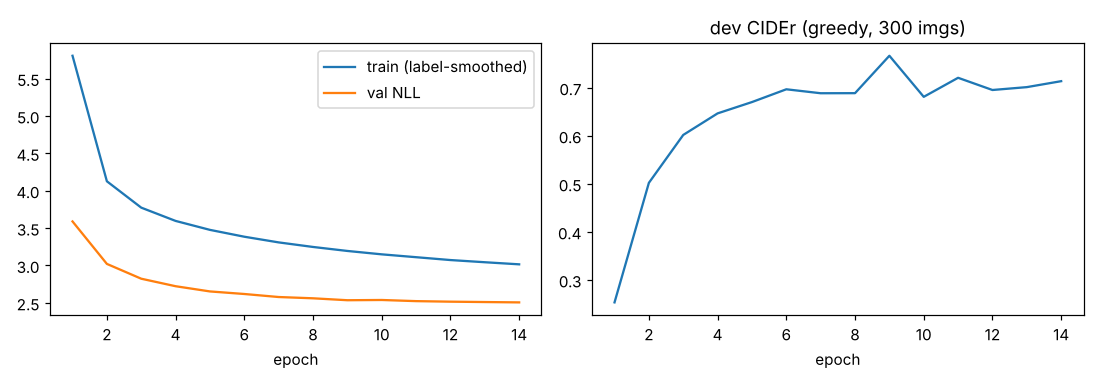

In [6]:
Image.open('results/training_curves.png')

## 4. Live captioning with the trained model (beam = 3)

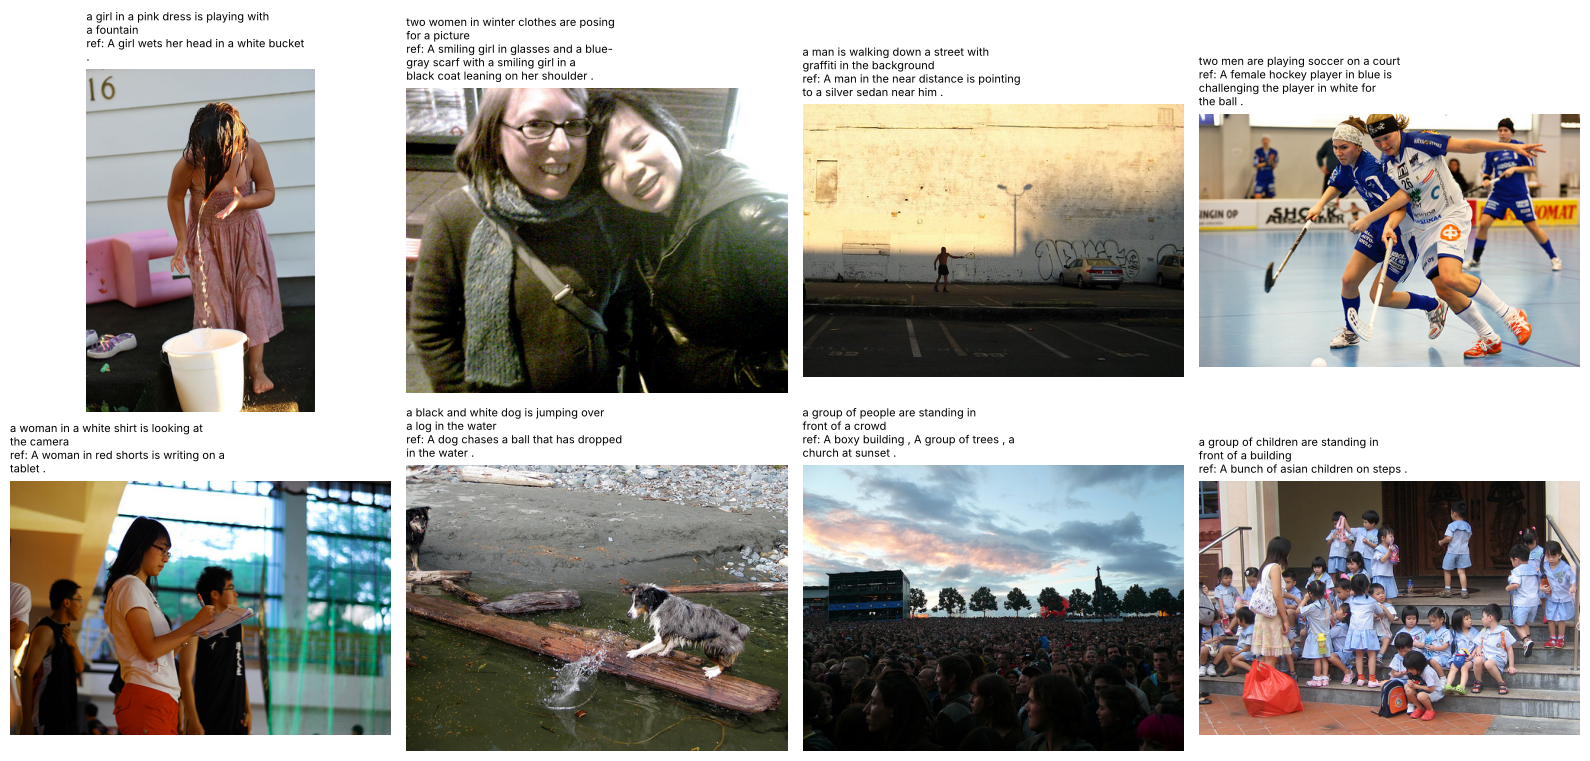

In [7]:
ck = torch.load('model/decoder_fp16.pt'); v = Vocab(ck['vocab'][4:]); m = Captioner(len(v)); m.load_state_dict({k: x.float() for k, x in ck['model'].items()}); m.eval()
def caption(name, beam=3): return v.decode(m.beam(torch.from_numpy(np.array(tok[idx[name]])).float(), beam=beam))
sel = split['test'][200:208]
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for a, n in zip(ax.ravel(), sel):
    a.imshow(Image.open(os.path.join(imgdir, n))); a.axis('off'); a.set_title(textwrap.fill(caption(n), 38) + '\nref: ' + textwrap.fill(caps[n][0], 38), fontsize=8, loc='left')
plt.tight_layout(); plt.show()

## 5. Best / random / worst test examples (per-image CIDEr with corpus-level idf)
Even among the 'worst' by CIDEr the captions are often plausible (a windsurfer called 'surfer', a dog/cow scene called 'two dogs'); real errors: rugby called soccer, generic 'group of people' captions for crowds.

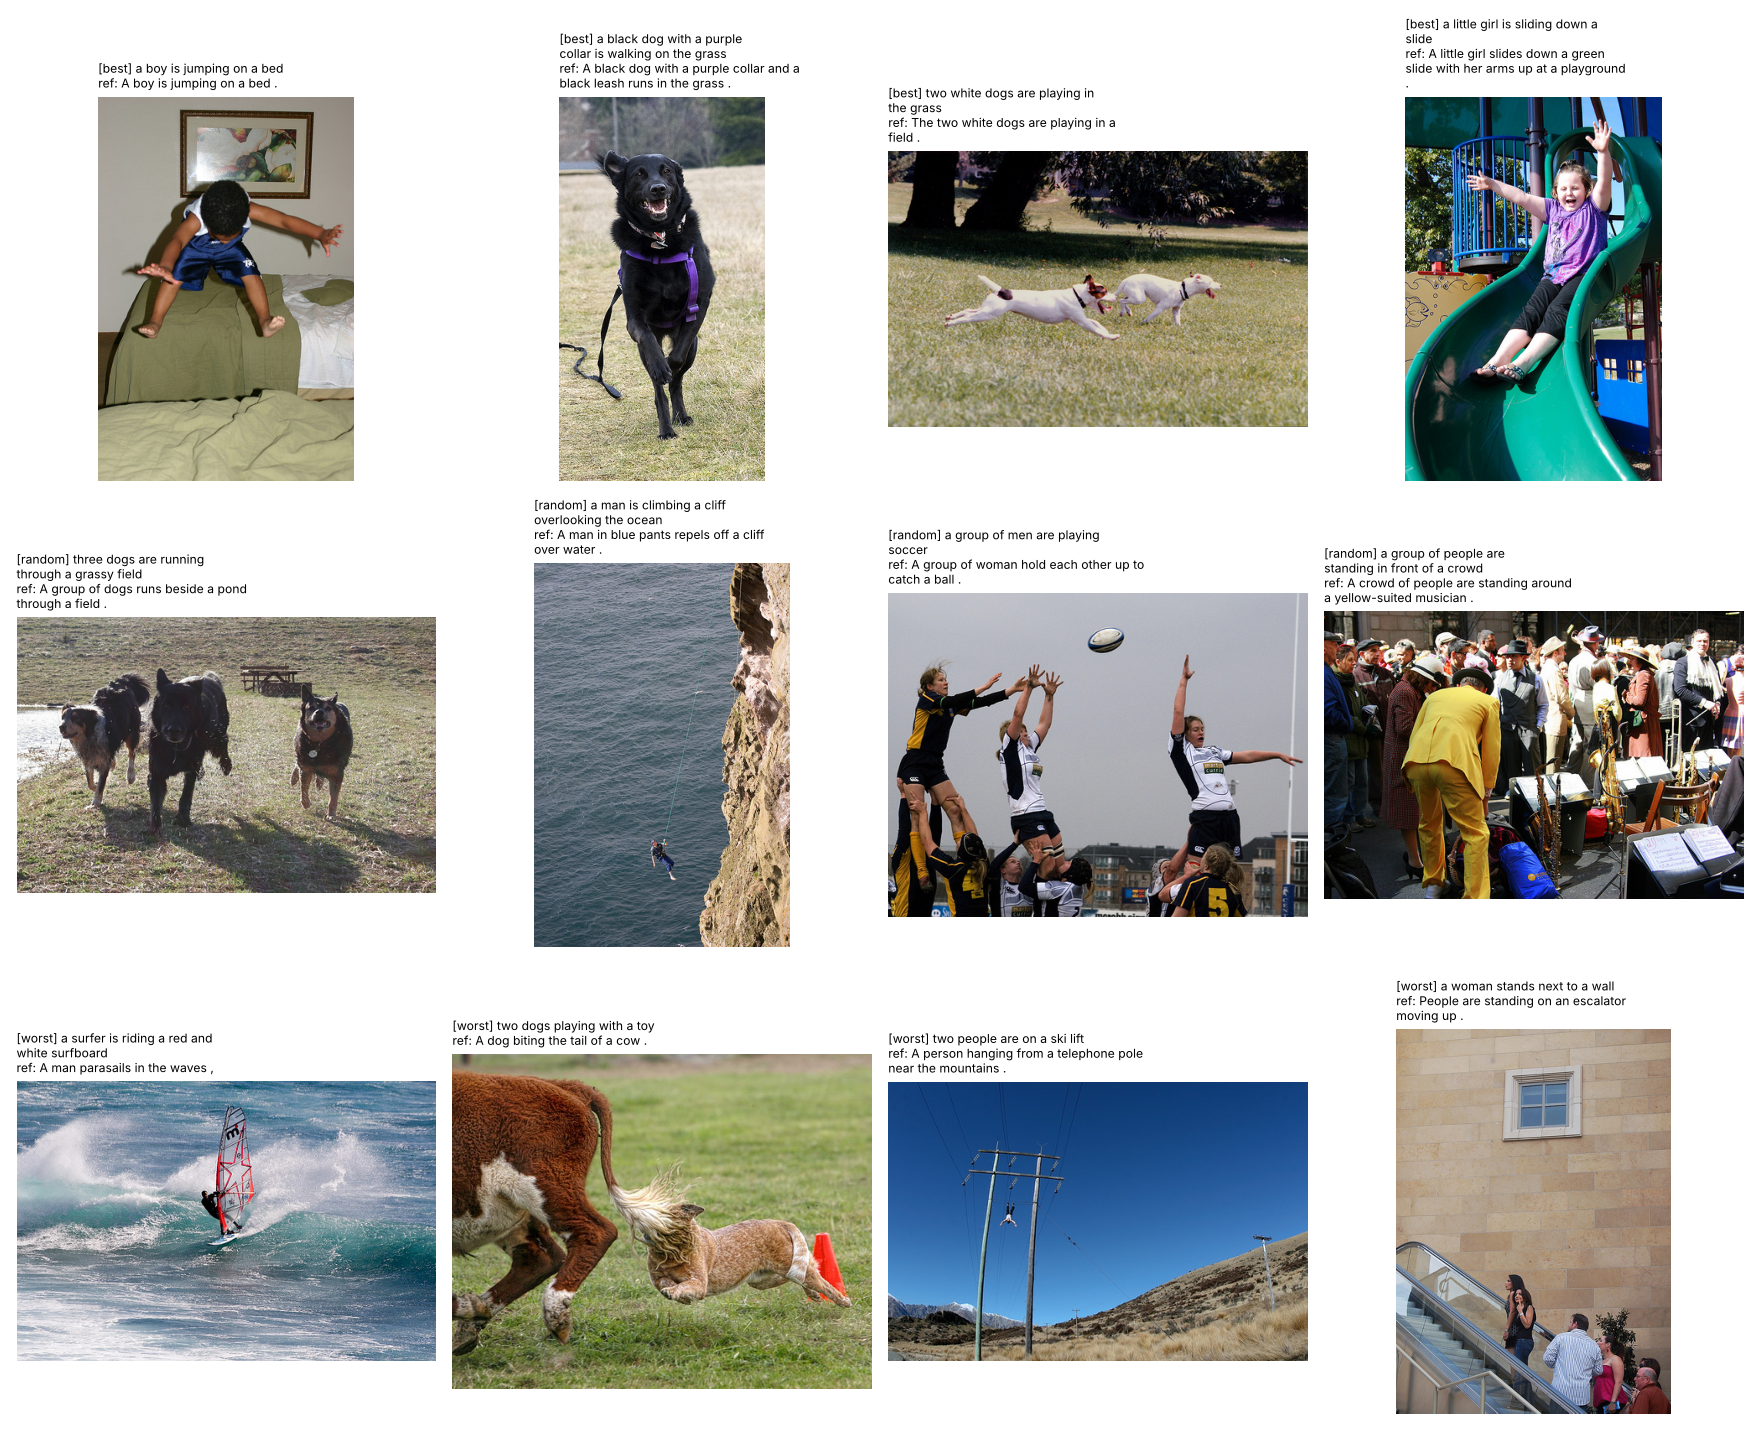

In [8]:
Image.open('results/sample_captions.png')

## 6. Honest limitations
- Pretrained generative LM (GPT-2/BLIP) was not usable (weights hosts blocked). The pretrained-text ablation uses CLIP's text transformer, which was trained contrastively, not as a generative LM; it gave no final gain.
- 3 seeds for the scratch decoder, 1 seed for the CLIP-text variant; dev selection uses 300 dev images with greedy CIDEr (noisy). Seed std is for the scratch model only.
- Dataset copy is the jbrownlee GitHub release, not Kaggle; official splits.
- Metrics are reference-overlap (BLEU/METEOR/ROUGE/CIDEr) plus CLIPScore; no human evaluation. Not compared to published numbers (tokenizer/split differences).